# T09 · Classification Workflow ครบวงจร (Baseline → หลายโมเดล → Optimize → เทียบก่อน/หลัง → เลือกโมเดล → ทำนาย)

**ใช้เมื่อโจทย์ถาม (แบบรวม):** *"สร้าง workflow ตั้งแต่ preprocessing → training → evaluation"* · *"สร้าง baseline แล้วเทียบ"* ·
*"เปรียบเทียบ KNN / Logistic / Decision Tree / Random Forest"* · *"hold-out หรือ cross-validation"* · *"optimize parameters"* ·
*"เปรียบเทียบก่อนและหลัง optimization"* · *"ควรเลือกโมเดลไหน เพราะอะไร"*

นี่คือ **template หลัก** ของโจทย์ classification — ถ้าโจทย์ถามลึกเฉพาะโมเดล ให้เปิด T05 (KNN) / T07 (Logistic) / T08 (Tree/RF) / T04 (imbalanced) ประกอบ

| ขั้น | ทำอะไร |
|---|---|
| 1 | แก้ **⚙️ CONFIG** — `TARGET`, `POS_LABEL`, `ID_COL`, `DROP_COLS`, `EVAL_MODE`, `PRIMARY_METRIC` |
| 2 | Run All → ตาราง §4 (default) · §5 (optimized) · §6 (ก่อน vs หลัง) · §7 (โมเดลสุดท้าย) |
| 3 | ไม่ต้องการโมเดลไหน → ลบออกจาก `MODELS` / `GRIDS` ใน §3 · ต้องการค่าพารามิเตอร์ตามโจทย์ → แก้ใน §3 |

In [1]:
# ════════ ⚙️ CONFIG — แก้ cell นี้ให้ตรงโจทย์ ════════
DATA_PATH = "../mock_lab/mock3_cluster_assoc/data/bank-data.csv"
TARGET    = "pep"
POS_LABEL = "YES"            # คลาสที่สนใจ (= 1)
ID_COL    = "id"
DROP_COLS = []               # คอลัมน์ที่ตัด (leak / ไม่เกี่ยว)
EVAL_MODE = "cv"             # "cv" = k-fold ทั้งชุด · "holdout" = tune ด้วย CV บน train แล้ววัดบน test
PRIMARY_METRIC = "f1"        # "f1" | "accuracy" | "recall" | "precision" (เลือกตามโจทย์/ความไม่สมดุล)
SCALE     = "standard"       # สำหรับ KNN / Logistic (Tree/RF ไม่ scale อัตโนมัติ)
USE_SMOTE = False            # True = ใส่ SMOTE ใน pipeline (เฉพาะ training fold)
NEW_DATA  = None             # dict / list / path .csv ของข้อมูลใหม่ · None = ข้าม
TEST_SIZE, N_FOLDS, SEED = 0.2, 10, 42
MISSING_MARKERS, SHEET, CSV_SEP = ["?", "", " ", "NA"], 0, ","

In [2]:
# ════════ 🔧 IMPORTS + HELPERS — ไม่ต้องแก้ cell นี้ แค่รันหลัง CONFIG ════════
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from sklearn.model_selection import (train_test_split, StratifiedKFold, KFold, cross_validate,
                                     cross_val_predict, GridSearchCV)
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import (StandardScaler, MinMaxScaler, OneHotEncoder, OrdinalEncoder,
                                   KBinsDiscretizer, LabelEncoder)
from sklearn.decomposition import PCA
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor, NearestNeighbors
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.tree import (DecisionTreeClassifier, DecisionTreeRegressor, plot_tree, export_text)
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             roc_curve, precision_recall_curve, average_precision_score,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report,
                             mean_absolute_error, mean_squared_error, r2_score,
                             silhouette_score, silhouette_samples, davies_bouldin_score)

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
plt.rcParams["figure.dpi"] = 100
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

# ค่า default ถ้า CONFIG ไม่ได้กำหนดไว้ (กันลืม)
for _name, _val in {"SEED": 42, "N_FOLDS": 5, "TEST_SIZE": 0.2, "TARGET": None, "POS_LABEL": None,
                    "ID_COL": None, "DROP_COLS": [], "MISSING_MARKERS": ["?", "", " ", "NA", "N/A", "null"],
                    "SHEET": 0, "CSV_SEP": ",", "SCALE": "standard"}.items():
    globals().setdefault(_name, _val)


def load_data(path, sheet=None, sep=None, na_values=None):
    """อ่าน .csv / .xlsx / .xls → ตัดช่องว่างหัวคอลัมน์และค่า string → แปลงค่าแฝง ('?', '') เป็น NaN"""
    sheet = SHEET if sheet is None else sheet
    sep = CSV_SEP if sep is None else sep
    na_values = MISSING_MARKERS if na_values is None else na_values
    if str(path).lower().endswith((".xlsx", ".xls")):
        df = pd.read_excel(path, sheet_name=sheet)
    else:
        for enc in ["utf-8-sig", "cp874", "latin1"]:      # utf-8 (ตัด BOM) → ภาษาไทยจาก Excel (cp874) → อื่น ๆ
            try:
                df = pd.read_csv(path, sep=sep, encoding=enc)
                break
            except UnicodeDecodeError:
                continue
        if df.shape[1] == 1 and ";" in str(df.columns[0]):  # ไฟล์คั่นด้วย ; แต่ตั้ง CSV_SEP = ","
            df = pd.read_csv(path, sep=";", encoding=enc)
            print("ℹ️ ไฟล์นี้คั่นด้วย ';' → อ่านใหม่ด้วย sep=';'")
    df.columns = [str(c).strip() for c in df.columns]
    for c in df.columns:
        if not pd.api.types.is_numeric_dtype(df[c]) and not pd.api.types.is_bool_dtype(df[c]):
            df[c] = df[c].map(lambda v: v.strip() if isinstance(v, str) else v)
    df = df.replace(list(na_values), np.nan)
    # คอลัมน์ที่เป็นตัวเลขแต่ถูกอ่านเป็น text (เพราะเคยมี '?') → แปลงกลับเป็นตัวเลข
    for c in df.columns:
        if not pd.api.types.is_numeric_dtype(df[c]) and not pd.api.types.is_bool_dtype(df[c]):
            conv = pd.to_numeric(df[c], errors="coerce")
            if conv.notna().sum() == df[c].notna().sum() and df[c].notna().any():
                df[c] = conv
    print(f"โหลด {path} → {df.shape[0]} แถว × {df.shape[1]} คอลัมน์")
    return df


def check(df, target=None):
    """ตรวจข้อมูลใน 1 คำสั่ง: ขนาด · ชนิด · ค่าว่าง · unique · ตัวอย่างค่า · สัดส่วน target"""
    print("shape:", df.shape, "| แถวซ้ำ:", int(df.duplicated().sum()))
    info = pd.DataFrame({"dtype": df.dtypes.astype(str),
                         "missing": df.isna().sum(),
                         "missing_%": (df.isna().mean() * 100).round(2),
                         "unique": df.nunique(),
                         "example": [df[c].dropna().iloc[0] if df[c].notna().any() else None for c in df]})
    display(info)
    if target is not None and target in df and pd.api.types.is_numeric_dtype(df[target]) and df[target].nunique() > 15:
        print(f"target '{target}' เป็นตัวเลข (regression):")
        display(df[target].describe().to_frame().T)
    elif target is not None and target in df:
        vc = pd.concat([df[target].value_counts(dropna=False), df[target].value_counts(normalize=True, dropna=False).round(4)],
                       axis=1, keys=["count", "ratio"])
        print(f"การกระจายของ target '{target}':")
        display(vc)


def fix_col(df, col, kind="any", i=0):
    """คอลัมน์ที่ตั้งไว้ใน ✏️ ไม่มีในข้อมูลนี้ → เลือกคอลัมน์ชนิดเดียวกันให้ชั่วคราว (Run All ไม่หยุด) — ควรแก้ ✏️ ให้ตรงโจทย์
    kind: "num" = ตัวเลขต่อเนื่อง · "cat" = หมวดหมู่ (ค่าไม่เกิน 20 แบบ) · "any" """
    if col is None or col in df.columns:
        return col
    skip = {ID_COL}
    nums = [c for c in num_cols(df) if c not in skip]
    if kind == "num":
        pool = [c for c in nums if df[c].nunique() > 10] or nums
    elif kind == "cat":
        few = [c for c in df.columns if c not in skip and df[c].nunique() <= 20]
        pool = [c for c in few if c not in nums] + [c for c in few if c in nums]
    else:
        pool = [c for c in df.columns if c not in skip]
    new = pool[min(i, len(pool) - 1)] if pool else None
    print(f"⚠️ ไม่มีคอลัมน์ {col!r} ในข้อมูลนี้ → ใช้ {new!r} แทนชั่วคราว (แก้บรรทัด ✏️ ให้ตรงโจทย์)")
    return new


def num_cols(df):
    return df.select_dtypes(include="number").columns.tolist()


def cat_cols(df):
    return [c for c in df.columns if c not in num_cols(df)]


def make_xy(df, target=None, drop=None, pos_label=None, task="classification"):
    """แยก X / y · ตัด target + DROP_COLS + ID_COL · classification 2 คลาส → y = 1 ถ้าเท่ากับ POS_LABEL"""
    target = TARGET if target is None else target
    drop = DROP_COLS if drop is None else drop
    pos_label = POS_LABEL if pos_label is None else pos_label
    d = df.dropna(subset=[target]).copy()
    removed = [c for c in list(drop) + [ID_COL] if c is not None and c in d.columns and c != target]
    X = d.drop(columns=[target] + removed)
    if task == "regression":
        y = d[target].astype(float)
        print(f"X: {X.shape} | y = '{target}' (ตัวเลข) | ตัดคอลัมน์: {removed}")
        return X, y
    raw = d[target]
    classes = sorted(raw.astype(str).unique())
    if len(classes) == 2:
        pos = str(pos_label) if pos_label is not None else classes[-1]
        if pos not in classes:
            raise ValueError(f"POS_LABEL={pos_label!r} ไม่อยู่ใน {classes} — แก้ใน CONFIG")
        neg = [c for c in classes if c != pos][0]
        y = (raw.astype(str) == pos).astype(int).rename(target)
        print(f"X: {X.shape} | y = '{target}' → 1 = {pos!r} (positive), 0 = {neg!r} | ตัดคอลัมน์: {removed}")
    else:
        y = raw.astype(str)
        print(f"X: {X.shape} | y = '{target}' มี {len(classes)} คลาส {classes} (multiclass → ใช้ macro avg) | ตัดคอลัมน์: {removed}")
    return X, y


def is_binary(y):
    return pd.Series(y).nunique() == 2


def build_prep(X, scale="config", num_impute="median", onehot=True):
    """preprocessing ที่ fit เฉพาะ train (ใส่ใน Pipeline → ไม่ leak)
    ตัวเลข: เติมค่าว่าง (median) → scale ('standard' z-score | 'minmax' 0–1 | None)
    หมวดหมู่: เติมค่าว่าง (ค่าที่พบบ่อยสุด) → one-hot"""
    if scale == "config":                      # ไม่ระบุ → ใช้ SCALE จาก CONFIG · ส่ง None = ไม่ scale
        scale = SCALE
    nums, cats = num_cols(X), cat_cols(X)
    scaler = {"standard": StandardScaler(), "minmax": MinMaxScaler()}.get(scale, "passthrough")
    num_pipe = Pipeline([("impute", SimpleImputer(strategy=num_impute)), ("scale", scaler)])
    enc = OneHotEncoder(handle_unknown="ignore", sparse_output=False) if onehot else \
        OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)
    cat_pipe = Pipeline([("impute", SimpleImputer(strategy="most_frequent")), ("encode", enc)])
    return ColumnTransformer([("num", num_pipe, nums), ("cat", cat_pipe, cats)],
                             verbose_feature_names_out=False)


def make_pipe(model, X, scale="config", **kw):
    """Pipeline = preprocessing (fit บน train fold เท่านั้น) + model"""
    return Pipeline([("prep", build_prep(X, scale=scale, **kw)), ("model", model)])


def get_cv(task="classification", n=None):
    n = N_FOLDS if n is None else n
    if task == "regression":
        return KFold(n_splits=n, shuffle=True, random_state=SEED)
    return StratifiedKFold(n_splits=n, shuffle=True, random_state=SEED)


def cls_scoring(y):
    if is_binary(y):
        return {"accuracy": "accuracy", "precision": "precision", "recall": "recall", "f1": "f1"}
    return {"accuracy": "accuracy", "precision": "precision_macro", "recall": "recall_macro", "f1": "f1_macro"}


def evaluate(name, model, X, y, cv=None, settings="", train=False):
    """classification ด้วย cross-validation → 1 แถว (ค่าเฉลี่ยทุก fold) ใช้ต่อเป็นตารางเปรียบเทียบ"""
    cv = get_cv() if cv is None else cv
    r = cross_validate(model, X, y, cv=cv, scoring=cls_scoring(y), return_train_score=train)
    row = {"model": name, "settings": settings}
    row.update({m: r[f"test_{m}"].mean() for m in ["accuracy", "precision", "recall", "f1"]})
    row["f1_std"] = r["test_f1"].std()
    if train:
        row["train_accuracy"] = r["train_accuracy"].mean()
    return row


def evaluate_holdout(name, model, X_tr, y_tr, X_te, y_te, settings=""):
    """classification แบบ hold-out: fit บน train → วัดบน test"""
    model.fit(X_tr, y_tr)
    p = model.predict(X_te)
    avg = "binary" if is_binary(y_tr) else "macro"
    return {"model": name, "settings": settings,
            "accuracy": accuracy_score(y_te, p),
            "precision": precision_score(y_te, p, average=avg, zero_division=0),
            "recall": recall_score(y_te, p, average=avg, zero_division=0),
            "f1": f1_score(y_te, p, average=avg, zero_division=0),
            "train_accuracy": accuracy_score(y_tr, model.predict(X_tr))}


def reg_metrics(y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    return {"MAE": float(mean_absolute_error(y_true, y_pred)), "MSE": float(mse), "RMSE": float(np.sqrt(mse)),
            "R2": float(r2_score(y_true, y_pred))}


def evaluate_reg(name, model, X, y, cv=None, settings=""):
    """regression ด้วย cross-validation → MAE / MSE / RMSE / R²"""
    cv = get_cv("regression") if cv is None else cv
    r = cross_validate(model, X, y, cv=cv,
                       scoring=["neg_mean_absolute_error", "neg_mean_squared_error", "r2"])
    mse = -r["test_neg_mean_squared_error"].mean()
    return {"model": name, "settings": settings, "MAE": -r["test_neg_mean_absolute_error"].mean(),
            "MSE": mse, "RMSE": np.sqrt(mse), "R2": r["test_r2"].mean()}


def show_cm(y_true, y_pred, title="Confusion matrix"):
    """confusion matrix (แถว = actual, คอลัมน์ = predicted) + classification report"""
    labels = sorted(pd.Series(y_true).unique(), key=str)
    cm = confusion_matrix(y_true, y_pred, labels=labels)
    display(pd.DataFrame(cm, index=[f"actual {l}" for l in labels], columns=[f"pred {l}" for l in labels]))
    if len(labels) == 2:
        tn, fp, fn, tp = cm.ravel()
        print(f"TN={tn}  FP={fp}  FN={fn}  TP={tp}")
    print(classification_report(y_true, y_pred, digits=4, zero_division=0))
    fig, ax = plt.subplots(figsize=(4, 3.4))
    ConfusionMatrixDisplay(cm, display_labels=labels).plot(ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(title); ax.grid(False); plt.show()


def top_k(grid, n=10):
    """ตารางผล GridSearchCV เรียงจากดีสุด"""
    res = pd.DataFrame(grid.cv_results_)
    cols = [c for c in res if c.startswith("param_")] + \
           [c for c in res if c.startswith("mean_test_") or c.startswith("mean_train_")]
    key = f"mean_test_{grid.refit}" if isinstance(grid.refit, str) else "mean_test_score"
    return res[cols].sort_values(key, ascending=False).head(n).reset_index(drop=True)


def results_table(rows, sort_by=None, ascending=False):
    t = pd.DataFrame(rows)
    if sort_by:
        t = t.sort_values(sort_by, ascending=ascending)
    display(t.reset_index(drop=True))
    return t.reset_index(drop=True)


def say_compare(table, metric="f1", baseline_name=None, higher_is_better=True):
    """พิมพ์ประโยคตีความสำเร็จรูปจากตารางผล (copy ไปใส่คำตอบได้เลย)"""
    t = table.sort_values(metric, ascending=not higher_is_better)
    best = t.iloc[0]
    msg = f"✍️ โมเดลที่ดีที่สุดตาม {metric} คือ {best['model']}"
    if str(best.get("settings", "")):
        msg += f" ({best['settings']})"
    msg += f" ได้ {metric} = {best[metric]:.4f}"
    if baseline_name is not None and baseline_name in set(table["model"]):
        b = table.loc[table["model"] == baseline_name].iloc[0]
        diff = best[metric] - b[metric]
        msg += f" เทียบกับ baseline ({baseline_name}) ที่ได้ {b[metric]:.4f} ต่างกัน {diff:+.4f}"
        if "accuracy" in table and metric != "accuracy":
            msg += f" (baseline accuracy = {b['accuracy']:.4f} แต่ {metric} ต่ำ → accuracy อย่างเดียวหลอกได้ถ้าคลาสไม่สมดุล)"
    print(msg)


def new_data(source):
    """ข้อมูลใหม่ที่จะทำนาย: path ไฟล์ (str) / dict 1 แถว / list ของ dict / DataFrame"""
    if source is None:
        return None
    if isinstance(source, str):
        return load_data(source)
    if isinstance(source, dict):
        return pd.DataFrame([source])
    if isinstance(source, list):
        return pd.DataFrame(source)
    return source.copy()


def align_new(df_new, X_ref):
    """จัดคอลัมน์ข้อมูลใหม่ให้ตรงกับ X ที่ใช้ train (คอลัมน์ที่ขาดเติม NaN → imputer จัดการ)"""
    missing = [c for c in X_ref.columns if c not in df_new.columns]
    if missing:
        print("⚠️ ข้อมูลใหม่ขาดคอลัมน์:", missing, "→ เติม NaN (imputer จะเติมให้)")
    return df_new.reindex(columns=X_ref.columns)

print("✅ helpers พร้อม | SEED =", SEED, "| N_FOLDS =", N_FOLDS)

✅ helpers พร้อม | SEED = 42 | N_FOLDS = 10


## §1 โหลด + ตรวจข้อมูล

In [3]:
df = load_data(DATA_PATH)
check(df, TARGET)
X, y = make_xy(df)
print("ตัวเลข:", num_cols(X)); print("หมวดหมู่ (จะ one-hot):", cat_cols(X))

โหลด ../mock_lab/mock3_cluster_assoc/data/bank-data.csv → 600 แถว × 12 คอลัมน์
shape: (600, 12) | แถวซ้ำ: 0


,dtype,missing,missing_%,unique,example
id,str,0,0.0000,600,ID12101
age,int64,0,0.0000,50,48
sex,str,0,0.0000,2,FEMALE
region,str,0,0.0000,4,INNER_CITY
income,float64,0,0.0000,599,"17,546.0000"
married,str,0,0.0000,2,NO
children,int64,0,0.0000,4,1
car,str,0,0.0000,2,NO
save_act,str,0,0.0000,2,NO
current_act,str,0,0.0000,2,NO


การกระจายของ target 'pep':


,count,ratio
pep,,
NO,326,0.5433
YES,274,0.4567


X: (600, 10) | y = 'pep' → 1 = 'YES' (positive), 0 = 'NO' | ตัดคอลัมน์: ['id']
ตัวเลข: ['age', 'income', 'children']
หมวดหมู่ (จะ one-hot): ['sex', 'region', 'married', 'car', 'save_act', 'current_act', 'mortgage']


## §2 แบ่งข้อมูล + กำหนดวิธีประเมิน
- **hold-out**: train (ใช้ CV เลือก/tune) → test (วัดครั้งเดียวตอนจบ) · เร็ว ใช้เมื่อข้อมูลเยอะ
- **k-fold CV**: ทุกแถวได้เป็น validation 1 ครั้ง → ค่าเสถียรกว่า · ใช้เมื่อข้อมูลน้อย
- ทั้งสองแบบ preprocessing อยู่ใน Pipeline → fit เฉพาะ train/training fold (ไม่ leak)

In [4]:
cv = get_cv()
if EVAL_MODE == "holdout":
    X_dev, X_test, y_dev, y_test = train_test_split(X, y, test_size=TEST_SIZE, stratify=y, random_state=SEED)
    print(f"hold-out: train {X_dev.shape} / test {X_test.shape} · tune ด้วย {N_FOLDS}-fold CV บน train")
else:
    X_dev, y_dev = X, y
    print(f"{N_FOLDS}-fold stratified CV บนข้อมูลทั้งหมด {X.shape}")

def score(name, model, settings=""):
    """ประเมิน 1 โมเดลตาม EVAL_MODE → 1 แถว"""
    if EVAL_MODE == "holdout":
        return evaluate_holdout(name, model, X_dev, y_dev, X_test, y_test, settings)
    return evaluate(name, model, X_dev, y_dev, cv, settings, train=True)

def pipe(model, scale="config"):
    if USE_SMOTE:
        from imblearn.pipeline import Pipeline as ImbPipeline
        from imblearn.over_sampling import SMOTE
        return ImbPipeline([("prep", build_prep(X, scale=scale)), ("smote", SMOTE(random_state=SEED)), ("model", model)])
    return make_pipe(model, X, scale=scale)

10-fold stratified CV บนข้อมูลทั้งหมด (600, 10)


## §3 Baseline + โมเดล default + grid สำหรับ optimize (✏️ แก้ค่าตามโจทย์ได้ที่นี่)
**baseline** = จุดอ้างอิงขั้นต่ำ: majority (ทายคลาสที่พบบ่อยสุดเสมอ) · stratified (สุ่มตามสัดส่วน) → โมเดลจริงต้องชนะ baseline

In [5]:
BASELINES = {"Majority baseline": DummyClassifier(strategy="most_frequent"),
             "Stratified random baseline": DummyClassifier(strategy="stratified", random_state=SEED)}

MODELS = {   # ✏️ ชื่อ: (pipeline, ข้อความ settings)
    "KNN":                 (pipe(KNeighborsClassifier(n_neighbors=5)), "k=5"),
    "Logistic Regression": (pipe(LogisticRegression(max_iter=5000)), "C=1, t=0.5"),
    "Decision Tree":       (pipe(DecisionTreeClassifier(random_state=SEED), scale=None), "gini, no depth limit"),
    "Random Forest":       (pipe(RandomForestClassifier(n_estimators=100, random_state=SEED), scale=None), "100 trees"),
}
GRIDS = {    # ✏️ ช่วงค่าที่จะลอง (ชื่อ model__<parameter>)
    "KNN": {"model__n_neighbors": list(range(1, 32, 2)), "model__weights": ["uniform", "distance"]},
    "Logistic Regression": {"model__C": [0.01, 0.1, 1, 10, 100], "model__class_weight": [None, "balanced"]},
    "Decision Tree": {"model__max_depth": [2, 3, 4, 5, 6, 8, 10, None], "model__min_samples_leaf": [1, 2, 5, 10],
                      "model__criterion": ["gini", "entropy"]},
    "Random Forest": {"model__n_estimators": [100, 300], "model__max_depth": [None, 5, 10],
                      "model__min_samples_leaf": [1, 3, 5]},
}
print("models:", list(MODELS), "| primary metric:", PRIMARY_METRIC)

models: ['KNN', 'Logistic Regression', 'Decision Tree', 'Random Forest'] | primary metric: f1


## §4 Baseline vs โมเดล default ⭐

,model,settings,accuracy,precision,recall,f1,f1_std,train_accuracy
0,Majority baseline,,0.5433,0.0000,0.0000,0.0000,0.0000,0.5433
1,Stratified random baseline,,0.5133,0.4640,0.4239,0.4430,0.0718,0.4856
2,KNN,k=5,0.7383,0.7377,0.6754,0.7008,0.0565,0.8367
3,Logistic Regression,"C=1, t=0.5",0.6233,0.6067,0.5254,0.5614,0.0614,0.6480
4,Decision Tree,"gini, no depth limit",0.8467,0.8332,0.8323,0.8325,0.0296,1.0000
5,Random Forest,100 trees,0.8550,0.8581,0.8217,0.8384,0.0472,1.0000


✍️ โมเดลที่ดีที่สุดตาม f1 คือ Random Forest (100 trees) ได้ f1 = 0.8384 เทียบกับ baseline (Majority baseline) ที่ได้ 0.0000 ต่างกัน +0.8384 (baseline accuracy = 0.5433 แต่ f1 ต่ำ → accuracy อย่างเดียวหลอกได้ถ้าคลาสไม่สมดุล)
⚠️ Decision Tree: train accuracy สูงกว่า validation 0.153 → overfit
⚠️ Random Forest: train accuracy สูงกว่า validation 0.145 → overfit


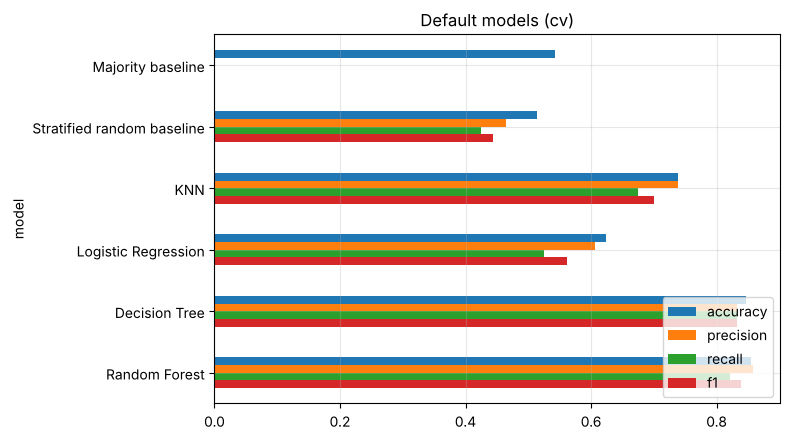

In [6]:
rows = [score(n, m) for n, m in BASELINES.items()]
rows += [score(n, m, s) for n, (m, s) in MODELS.items()]
default_tab = results_table(rows)
say_compare(default_tab, PRIMARY_METRIC, "Majority baseline")
if "train_accuracy" in default_tab:
    gap = (default_tab["train_accuracy"] - default_tab["accuracy"]).round(4)
    for n, g in zip(default_tab["model"], gap):
        if g > 0.1:
            print(f"⚠️ {n}: train accuracy สูงกว่า validation {g:.3f} → overfit")
default_tab.set_index("model")[["accuracy", "precision", "recall", "f1"]].plot(kind="barh", figsize=(8, 4.5), title=f"Default models ({EVAL_MODE})")
plt.gca().invert_yaxis(); plt.legend(loc="lower right"); plt.tight_layout(); plt.show()

**✍️ คำตอบ §4:** baseline (majority) ได้ accuracy … F1 … · โมเดล default ที่ดีที่สุดคือ … (… = …) ชนะ baseline … → โมเดลเรียนรู้รูปแบบได้จริง · … overfit (train … vs validation …)

## §5 Optimize parameters (GridSearchCV บน train/CV — เลือกด้วย PRIMARY_METRIC)

In [7]:
grids, best_rows = {}, []
for n, grid_params in GRIDS.items():
    if n not in MODELS:
        continue
    g = GridSearchCV(MODELS[n][0], grid_params, cv=cv, scoring=cls_scoring(y), refit=PRIMARY_METRIC, n_jobs=-1).fit(X_dev, y_dev)
    grids[n] = g
    print(f"── {n}: best {g.best_params_} · CV {PRIMARY_METRIC} = {g.best_score_:.4f}")
    display(top_k(g, 3))
    best_rows.append(score(f"{n} (optimized)", g.best_estimator_, str({k.replace('model__', ''): v for k, v in g.best_params_.items()})))
opt_tab = results_table(best_rows)

── KNN: best {'model__n_neighbors': 19, 'model__weights': 'distance'} · CV f1 = 0.7271


,param_model__n_neighbors,param_model__weights,mean_test_accuracy,mean_test_precision,mean_test_recall,mean_test_f1
0,19,distance,0.7683,0.7898,0.6790,0.7271
1,13,distance,0.7600,0.7702,0.6864,0.7223
2,11,distance,0.7550,0.7553,0.6935,0.7205


── Logistic Regression: best {'model__C': 1, 'model__class_weight': 'balanced'} · CV f1 = 0.5932


,param_model__C,param_model__class_weight,mean_test_accuracy,mean_test_precision,mean_test_recall,mean_test_f1
0,1.0000,balanced,0.6133,0.5754,0.6171,0.5932
1,10.0000,balanced,0.6117,0.5739,0.6135,0.5907
2,100.0000,balanced,0.6117,0.5739,0.6135,0.5907


── Decision Tree: best {'model__criterion': 'gini', 'model__max_depth': 6, 'model__min_samples_leaf': 5} · CV f1 = 0.8759


,param_model__criterion,param_model__max_depth,param_model__min_samples_leaf,mean_test_accuracy,mean_test_precision,mean_test_recall,mean_test_f1
0,gini,6,5,0.8900,0.9054,0.8507,0.8759
1,entropy,6,5,0.8900,0.9054,0.8507,0.8759
2,gini,6,2,0.8867,0.9005,0.8471,0.8719


── Random Forest: best {'model__max_depth': None, 'model__min_samples_leaf': 5, 'model__n_estimators': 100} · CV f1 = 0.8423


,param_model__max_depth,param_model__min_samples_leaf,param_model__n_estimators,mean_test_accuracy,mean_test_precision,mean_test_recall,mean_test_f1
0,None,5,100,0.8600,0.8706,0.8179,0.8423
1,10,3,300,0.8600,0.8735,0.8148,0.8416
2,10,5,100,0.8583,0.8717,0.8107,0.8393


,model,settings,accuracy,precision,recall,f1,f1_std,train_accuracy
0,KNN (optimized),"{'n_neighbors': 19, 'weights': 'distance'}",0.7683,0.7898,0.6790,0.7271,0.0305,1.0000
1,Logistic Regression (optimized),"{'C': 1, 'class_weight': 'balanced'}",0.6133,0.5754,0.6171,0.5932,0.0481,0.6369
2,Decision Tree (optimized),"{'criterion': 'gini', 'max_depth': 6, 'min_sam...",0.8900,0.9054,0.8507,0.8759,0.0375,0.9133
3,Random Forest (optimized),"{'max_depth': None, 'min_samples_leaf': 5, 'n_...",0.8600,0.8706,0.8179,0.8423,0.0460,0.9243


## §6 เปรียบเทียบก่อน vs หลัง optimize ⭐

,model,settings ก่อน,settings หลัง,f1 ก่อน,f1 หลัง,เปลี่ยน,accuracy ก่อน,accuracy หลัง
0,KNN,k=5,"{'n_neighbors': 19, 'weights': 'distance'}",0.7008,0.7271,0.0262,0.7383,0.7683
1,Logistic Regression,"C=1, t=0.5","{'C': 1, 'class_weight': 'balanced'}",0.5614,0.5932,0.0318,0.6233,0.6133
2,Decision Tree,"gini, no depth limit","{'criterion': 'gini', 'max_depth': 6, 'min_sam...",0.8325,0.8759,0.0435,0.8467,0.8900
3,Random Forest,100 trees,"{'max_depth': None, 'min_samples_leaf': 5, 'n_...",0.8384,0.8423,0.0039,0.8550,0.8600


✍️ KNN: f1 0.7008 → 0.7271 (+0.0262) ด้วย {'n_neighbors': 19, 'weights': 'distance'}
✍️ Logistic Regression: f1 0.5614 → 0.5932 (+0.0318) ด้วย {'C': 1, 'class_weight': 'balanced'}
✍️ Decision Tree: f1 0.8325 → 0.8759 (+0.0435) ด้วย {'criterion': 'gini', 'max_depth': 6, 'min_samples_leaf': 5}
✍️ Random Forest: f1 0.8384 → 0.8423 (+0.0039) ด้วย {'max_depth': None, 'min_samples_leaf': 5, 'n_estimators': 100}


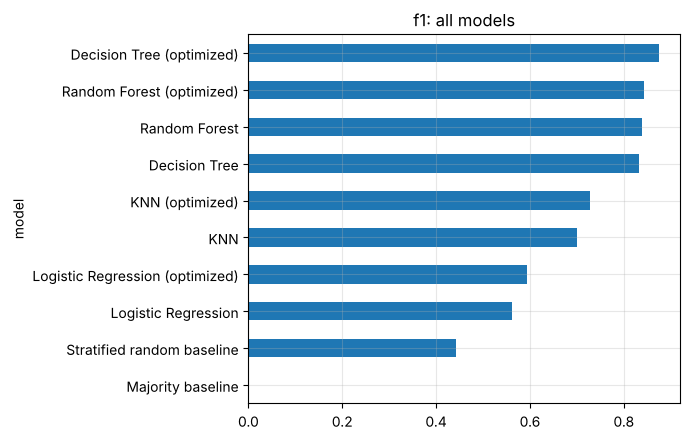

In [8]:
ba = []
for n in grids:
    before = default_tab.set_index("model").loc[n]; after = opt_tab.set_index("model").loc[f"{n} (optimized)"]
    ba.append({"model": n, "settings ก่อน": MODELS[n][1], "settings หลัง": after["settings"],
               f"{PRIMARY_METRIC} ก่อน": before[PRIMARY_METRIC], f"{PRIMARY_METRIC} หลัง": after[PRIMARY_METRIC],
               "เปลี่ยน": after[PRIMARY_METRIC] - before[PRIMARY_METRIC],
               "accuracy ก่อน": before["accuracy"], "accuracy หลัง": after["accuracy"]})
ba = results_table(ba)
for _, r in ba.iterrows():
    print(f"✍️ {r['model']}: {PRIMARY_METRIC} {r[f'{PRIMARY_METRIC} ก่อน']:.4f} → {r[f'{PRIMARY_METRIC} หลัง']:.4f} ({r['เปลี่ยน']:+.4f}) ด้วย {r['settings หลัง']}")
all_tab = pd.concat([default_tab, opt_tab], ignore_index=True)
all_tab.set_index("model")[PRIMARY_METRIC].sort_values().plot(kind="barh", figsize=(7, 4.5), title=f"{PRIMARY_METRIC}: all models"); plt.tight_layout(); plt.show()

## §7 เลือกโมเดลสุดท้าย → confusion matrix

✍️ โมเดลสุดท้าย = Decision Tree (optimized) (f1 = 0.8759)


,pred 0,pred 1
actual 0,301,25
actual 1,41,233


TN=301  FP=25  FN=41  TP=233
              precision    recall  f1-score   support

           0     0.8801    0.9233    0.9012       326
           1     0.9031    0.8504    0.8759       274

    accuracy                         0.8900       600
   macro avg     0.8916    0.8868    0.8886       600
weighted avg     0.8906    0.8900    0.8897       600



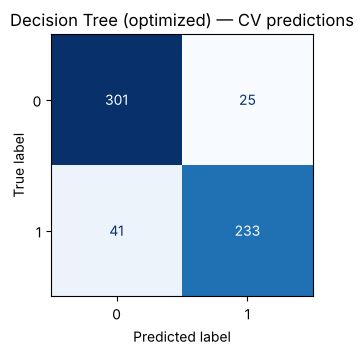

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](10,)","['age','sex','region',...,'save_act','current_act','mortgage']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,10
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_na

In [9]:
cand = all_tab[~all_tab["model"].str.contains("baseline")]
final_name = cand.loc[cand[PRIMARY_METRIC].idxmax(), "model"]
lookup = {n: m for n, (m, _) in MODELS.items()} | {f"{n} (optimized)": g.best_estimator_ for n, g in grids.items()}
final_model = lookup[final_name]
print(f"✍️ โมเดลสุดท้าย = {final_name} ({PRIMARY_METRIC} = {cand[PRIMARY_METRIC].max():.4f})")
if EVAL_MODE == "holdout":
    final_model.fit(X_dev, y_dev); show_cm(y_test, final_model.predict(X_test), f"{final_name} — test")
else:
    show_cm(y, cross_val_predict(final_model, X, y, cv=cv), f"{final_name} — CV predictions")
final_model.fit(X, y)       # fit ด้วยข้อมูลทั้งหมดก่อนใช้งานจริง

**✍️ คำตอบ §7 (โครงคำตอบ 4 ขั้น):**
1. **Process:** อ่านข้อมูล → ตัด `…` → Pipeline (median/mode imputer + z-score + one-hot) → {EVAL_MODE} → baseline + 4 โมเดล → GridSearch
2. **Settings:** seed …, … folds, metric หลัก … เพราะ …
3. **Results:** ตาราง §4–§6 · โมเดลที่ดีที่สุด … ได้ … = …
4. **Interpretation:** ดีกว่า baseline … · optimize แล้วดีขึ้น … · confusion matrix: FN … FP … → …

## §8 ทำนายข้อมูลใหม่

In [10]:
if NEW_DATA is not None:
    nd = align_new(new_data(NEW_DATA), X)
    out = nd.copy(); out["pred (1 = POS_LABEL)"] = final_model.predict(nd)
    if hasattr(final_model, "predict_proba"):
        out["P(1)"] = final_model.predict_proba(nd)[:, -1]
    display(out)
else:
    print("NEW_DATA = None → ข้าม (ตัวอย่างทำนาย 3 แถวแรก):")
    display(X.head(3).assign(pred=final_model.predict(X.head(3)), actual=y.head(3).values))

NEW_DATA = None → ข้าม (ตัวอย่างทำนาย 3 แถวแรก):


,age,sex,region,income,married,children,car,save_act,current_act,mortgage,pred,actual
0,48,FEMALE,INNER_CITY,"17,546.0000",NO,1,NO,NO,NO,NO,1,1
1,40,MALE,TOWN,"30,085.1000",YES,3,YES,NO,YES,YES,0,0
2,51,FEMALE,INNER_CITY,"16,575.4000",YES,0,YES,YES,YES,NO,0,0
